# 06 - Customer Churn: Comparing Many Models Properly
**Topic:** Classification  |  **Reference method:** "Compare Multiple Machine Learning Models" (amanxai.com, Feb 2024)

**About the source.** That article trains several *regression* models on a 414-row house-price file and ranks them by one test-set score. The list has no other model-comparison project, so I keep its **method** (train a diverse set of models, compare them on metrics *and* cost, pick one) and apply it to a classification problem that is new to me: **which telecom customers will churn?**

**Why comparing models is harder than it looks:** one split gives one number, and small differences are noise. I use repeated cross-validation, show the spread, test whether differences are real (corrected paired t-test), and weigh accuracy against training time.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
df = pd.read_csv("../_data/telco.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.shape, "| rows with blank TotalCharges:", int(df.TotalCharges.isna().sum()), "(all have tenure = 0:", bool((df.loc[df.TotalCharges.isna(), "tenure"] == 0).all()), ")")
df["TotalCharges"] = df["TotalCharges"].fillna(0)      # brand-new customers have not been billed yet
df["y"] = (df.Churn == "Yes").astype(int); df = df.drop(columns="Churn")
print("churn rate: %.1f%%" % (df.y.mean() * 100)); df.head(3).T

(7043, 20) | rows with blank TotalCharges: 11 (all have tenure = 0: True )
churn rate: 26.5%


,0,1,2
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,'No phone service',No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes
OnlineBackup,Yes,No,Yes


## 2. Look at the data first

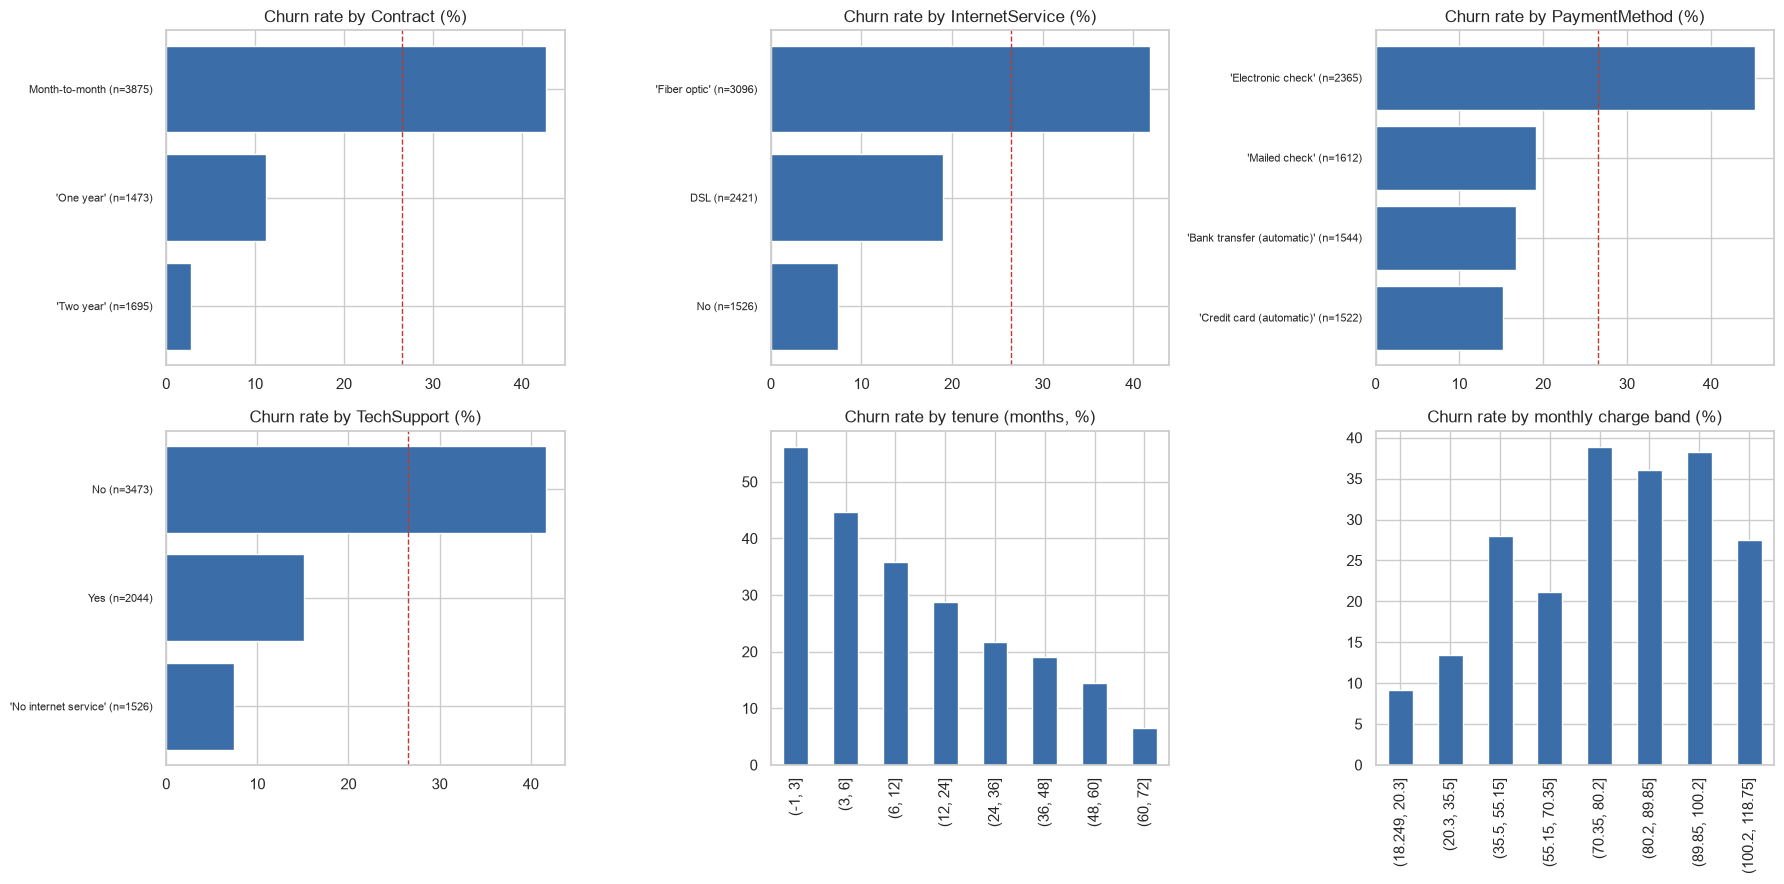

In [2]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for a, c in zip(ax.ravel()[:4], ["Contract", "InternetService", "PaymentMethod", "TechSupport"]):
    g = df.groupby(c)["y"].agg(["mean", "size"]).sort_values("mean"); a.barh([f"{k} (n={n})" for k, n in zip(g.index, g["size"])], g["mean"] * 100, color="#3b6ea8"); a.axvline(df.y.mean() * 100, color="#c0392b", ls="--", lw=1)
    a.set_title(f"Churn rate by {c} (%)"); a.tick_params(axis="y", labelsize=8)
df.assign(b=pd.cut(df.tenure, [-1, 3, 6, 12, 24, 36, 48, 60, 72])).groupby("b", observed=True)["y"].mean().mul(100).plot.bar(ax=ax[1, 1], color="#3b6ea8"); ax[1, 1].set_title("Churn rate by tenure (months, %)"); ax[1, 1].set_xlabel("")
df.assign(b=pd.qcut(df.MonthlyCharges, 8)).groupby("b", observed=True)["y"].mean().mul(100).plot.bar(ax=ax[1, 2], color="#3b6ea8"); ax[1, 2].set_title("Churn rate by monthly charge band (%)"); ax[1, 2].set_xlabel("")
plt.tight_layout(); plt.show()

**Reading it.** (churn rate overall 26.5%)
* **Contract type:** month-to-month customers churned 42.7% (3,875 customers), one-year 11.3%, two-year 2.8%.
* **Tenure:** churn falls steadily with time as a customer: 56% in the first 3 months, 36% at 6-12 months, 7% after 5 years.
* **Service and payment:** fibre-optic customers churn 41.9% vs 19.0% for DSL; electronic-check payers 45.3% vs about 15-19% for the other payment methods; customers without tech support 41.6% vs 15.2% with it.
* Monthly charge shows no simple pattern (a rise, then fall at the top bands). All of these are associations: customers on short contracts are also newer, on different products, and so on; the chart cannot say that changing a contract would change churn.

## 3. Twelve models, one protocol
Same preprocessing for all (numbers standardised, categories one-hot), same folds: **5-fold stratified CV repeated 3 times (15 fits per model)**. Metrics: ROC-AUC, PR-AUC (average precision; better for a 27% minority) and fit time. Defaults are close to library defaults with light regularisation; **no per-model tuning**, which would be needed for a final choice.

In [3]:
num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat = [c for c in df.columns if c not in num + ["y"]]
pre = lambda: ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
X, y = df.drop(columns="y"), df.y
M = {
 "majority class": DummyClassifier(strategy="prior"),
 "logistic regression": LogisticRegression(C=0.5, max_iter=3000),
 "k-nearest neighbours (k=25)": KNeighborsClassifier(25),
 "naive Bayes": GaussianNB(),
 "decision tree (depth 5)": DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=0),
 "random forest": RandomForestClassifier(300, min_samples_leaf=5, n_jobs=-1, random_state=0),
 "extra trees": ExtraTreesClassifier(300, min_samples_leaf=5, n_jobs=-1, random_state=0),
 "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=.5, random_state=0),
 "gradient boosting (sklearn)": HistGradientBoostingClassifier(learning_rate=.05, max_iter=150, max_depth=3, l2_regularization=1.0, random_state=0),
 "XGBoost": XGBClassifier(n_estimators=250, learning_rate=.04, max_depth=3, subsample=.8, colsample_bytree=.8, n_jobs=4, random_state=0, verbosity=0),
 "LightGBM": LGBMClassifier(n_estimators=250, learning_rate=.04, num_leaves=8, subsample=.8, subsample_freq=1, colsample_bytree=.8, random_state=0, verbose=-1, n_jobs=4),
 "CatBoost": CatBoostClassifier(iterations=300, learning_rate=.05, depth=4, random_seed=0, verbose=0, thread_count=4),
 "SVM (RBF)": SVC(C=1.0, gamma="scale"),
 "neural net (64,32)": MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-2, early_stopping=True, max_iter=500, random_state=0),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
auc, ap, tfit = {}, {}, {}
for name, m in M.items():
    r = cross_validate(make_pipeline(pre(), m), X, y, cv=cv, scoring=["roc_auc", "average_precision"], n_jobs=1)
    auc[name], ap[name], tfit[name] = r["test_roc_auc"], r["test_average_precision"], r["fit_time"].mean()
res = pd.DataFrame({"AUC": {k: v.mean() for k, v in auc.items()}, "AUC_sd": {k: v.std() for k, v in auc.items()}, "PR_AUC": {k: v.mean() for k, v in ap.items()}, "fit_seconds": tfit}).sort_values("AUC", ascending=False)
print(res.round(3).to_string())

                               AUC  AUC_sd  PR_AUC  fit_seconds
XGBoost                      0.849   0.013   0.668        0.423
AdaBoost                     0.848   0.013   0.666        0.877
LightGBM                     0.848   0.013   0.668        0.157
gradient boosting (sklearn)  0.848   0.013   0.666        0.355
CatBoost                     0.848   0.013   0.665        0.643
logistic regression          0.845   0.014   0.655        0.050
random forest                0.845   0.012   0.658        0.667
neural net (64,32)           0.841   0.012   0.645        0.583
extra trees                  0.837   0.013   0.640        0.589
decision tree (depth 5)      0.830   0.014   0.612        0.044
k-nearest neighbours (k=25)  0.830   0.012   0.607        0.050
naive Bayes                  0.818   0.016   0.608        0.040
SVM (RBF)                    0.799   0.011   0.636        0.531
majority class               0.500   0.000   0.265        0.031


**Reading it.**
* **Five boosted-tree models and logistic regression are within 0.004 AUC of each other** (0.845-0.849). The spread across folds for any one model (about 0.013) is several times larger than the gap between them.
* **Logistic regression, with the smallest fit time (0.05 s vs 0.14-0.8 s), is as good as the sophisticated methods here.** Tabular data with mostly categorical, roughly additive effects often behaves this way; that is a finding about *this* problem, not a general rule.
* Clearly worse: extra trees, a depth-5 tree, k-NN, naive Bayes (0.82-0.84), and an **untuned** RBF SVM (0.80, AUC computed from its decision scores). An SVM or network could improve with tuning; I did not tune any model.
* The majority-class model has AUC 0.5 and PR-AUC equal to the churn rate (0.265): the floor.

## 4. Are the differences real? Corrected paired t-test against the best model
The 15 folds overlap, so a plain t-test is over-confident. The **Nadeau-Bengio correction** inflates the variance by `(1/k + n_test/n_train)`. For each model I test `AUC(model) - AUC(best)` over the 15 paired folds.

In [4]:
best = res.index[0]; k = 15; n_test_over_train = 0.25
rows = []
for name in res.index[1:]:
    d = auc[best] - auc[name]; var = d.var(ddof=1)
    t = d.mean() / np.sqrt((1 / k + n_test_over_train) * var) if var > 0 else np.inf
    rows.append([name, d.mean(), t, 2 * stats.t.sf(abs(t), k - 1)])
cmp_ = pd.DataFrame(rows, columns=["model", f"AUC gap to {best}", "t (corrected)", "p_value"]).set_index("model")
print(cmp_.round(4).to_string())
n_tied = int((cmp_.p_value > 0.05).sum()); print("\n%d of %d models are NOT statistically distinguishable from the best at p < 0.05 (uncorrected for the %d comparisons)" % (n_tied, len(cmp_), len(cmp_)))

                             AUC gap to XGBoost  t (corrected)  p_value
model                                                                  
AdaBoost                                 0.0001         0.0871   0.9318
LightGBM                                 0.0002         0.2405   0.8135
gradient boosting (sklearn)              0.0003         0.5042   0.6219
CatBoost                                 0.0008         0.9990   0.3348
logistic regression                      0.0034         1.6688   0.1174
random forest                            0.0039         2.0657   0.0579
neural net (64,32)                       0.0076         1.8682   0.0828
extra trees                              0.0112         3.1338   0.0073
decision tree (depth 5)                  0.0182         6.6959   0.0000
k-nearest neighbours (k=25)              0.0185         4.5023   0.0005
naive Bayes                              0.0306         5.9169   0.0000
SVM (RBF)                                0.0500        11.4506  

**Reading it.** With the correction, **7 of 13 models cannot be distinguished from the best** (XGBoost) at the 5% level, including logistic regression (p = 0.12) and random forest (p = 0.058). Models that are clearly worse: extra trees (p = 0.007), the shallow tree, k-NN, naive Bayes, SVM and the majority baseline. The p-values are not adjusted for 13 comparisons, which would make even fewer differences significant. So the honest ranking is "a top group of seven, then the rest", not "XGBoost wins".

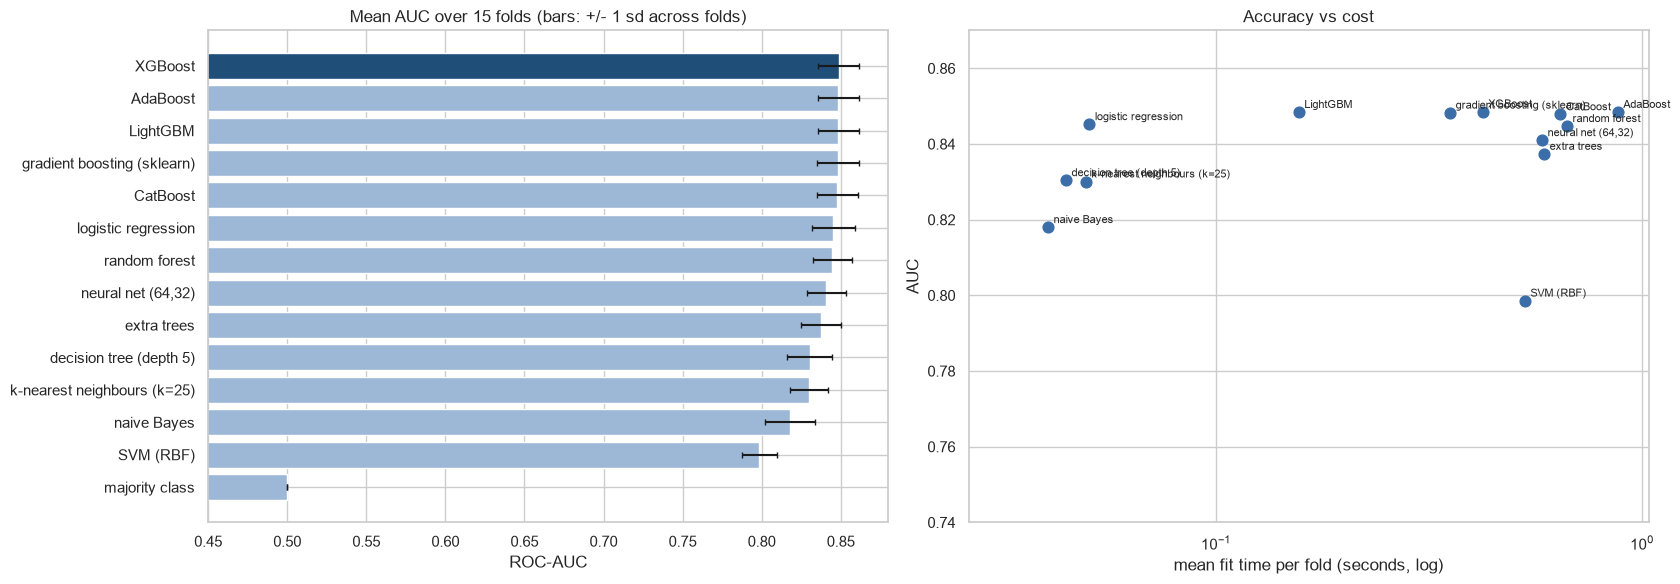

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
o = res.sort_values("AUC"); ax[0].barh(o.index, o.AUC, xerr=o.AUC_sd, color=["#1f4e79" if i == best else "#9db8d6" for i in o.index], ecolor="k", capsize=2)
ax[0].set_xlim(.45, .88); ax[0].set_title("Mean AUC over 15 folds (bars: +/- 1 sd across folds)"); ax[0].set_xlabel("ROC-AUC")
ax[1].scatter(res.fit_seconds, res.AUC, s=60, color="#3b6ea8")
for n, r in res.iterrows(): ax[1].annotate(n, (r.fit_seconds, r.AUC), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax[1].set_xscale("log"); ax[1].set_xlabel("mean fit time per fold (seconds, log)"); ax[1].set_ylabel("AUC"); ax[1].set_ylim(.74, .87); ax[1].set_title("Accuracy vs cost")
plt.tight_layout(); plt.show()

**Reading it.** The left panel shows how crowded the top is: the error bars (fold-to-fold spread) overlap for the top seven. The right panel shows the accuracy-cost trade: logistic regression is both fast and in the top group, so it is the sensible default; XGBoost/LightGBM add little. Fit times here are for a 7,000-row table; at larger scale the cost gap would matter more.

## 5. What does the ranking buy the business? Gain by decile (out-of-fold)
Rank customers by predicted churn probability and look at how many churners sit in the top deciles. A retention campaign can only contact so many people. The *money* part below uses **assumed** numbers: replace them with the company's.

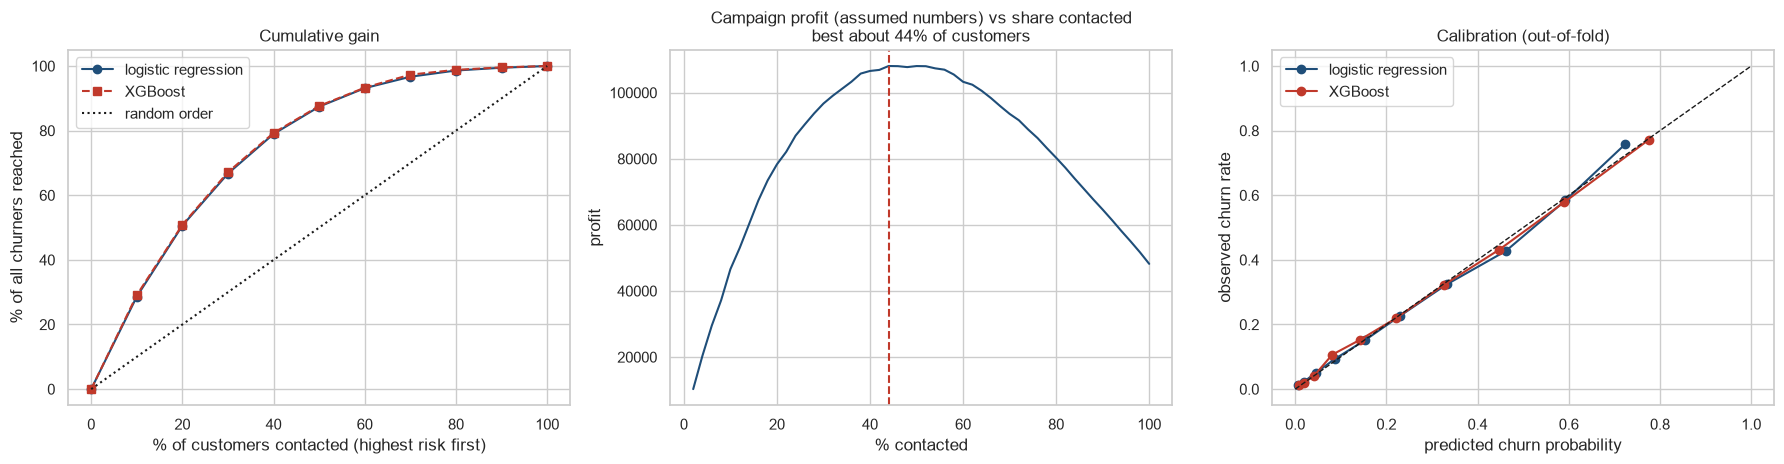

top 10% of customers by risk contain 29% of churners (logistic) / 29% (XGBoost); top 30%: 67% / 67%
assumed economics: save 30% of contacted churners, worth 400 each, 25 per contact. Best share to contact: 44% -> profit 108070 (contact nobody = 0; contact everybody = 48205)


In [6]:
pipe = lambda name: make_pipeline(pre(), M[name])
oof = cross_val_predict(pipe("logistic regression"), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=1), method="predict_proba")[:, 1]
oof_b = cross_val_predict(pipe(best), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=1), method="predict_proba")[:, 1]
def gain(p):
    d = pd.DataFrame({"p": p, "y": y.to_numpy()}).sort_values("p", ascending=False).reset_index(drop=True); d["dec"] = d.index * 10 // len(d) + 1
    g = d.groupby("dec").y.agg(["sum", "mean"]); g["cum_share_of_churners"] = g["sum"].cumsum() / d.y.sum(); return g
g1, g2 = gain(oof), gain(oof_b)
VALUE_SAVED, COST_CONTACT, SAVE_RATE = 400.0, 25.0, 0.30      # ASSUMED: value of a retained customer, cost per contact, share of contacted churners we retain
def profit(p, frac):
    n = int(frac * len(p)); idx = np.argsort(-p)[:n]; return (y.to_numpy()[idx].sum() * SAVE_RATE * VALUE_SAVED) - n * COST_CONTACT
fr = np.linspace(.02, 1, 50); pr = [profit(oof, f) for f in fr]; f_best = float(fr[int(np.argmax(pr))])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].plot([0] + list(g1.index * 10), [0] + list(g1.cum_share_of_churners * 100), "o-", color="#1f4e79", label="logistic regression"); ax[0].plot([0] + list(g2.index * 10), [0] + list(g2.cum_share_of_churners * 100), "s--", color="#c0392b", label=best)
ax[0].plot([0, 100], [0, 100], "k:", label="random order"); ax[0].set_xlabel("% of customers contacted (highest risk first)"); ax[0].set_ylabel("% of all churners reached"); ax[0].set_title("Cumulative gain"); ax[0].legend()
ax[1].plot(fr * 100, pr, color="#1f4e79"); ax[1].axvline(f_best * 100, color="#c0392b", ls="--"); ax[1].set_title(f"Campaign profit (assumed numbers) vs share contacted\nbest about {f_best*100:.0f}% of customers"); ax[1].set_xlabel("% contacted"); ax[1].set_ylabel("profit")
for nm, p, c in [("logistic regression", oof, "#1f4e79"), (best, oof_b, "#c0392b")]:
    fp, mp = calibration_curve(y, p, n_bins=10, strategy="quantile"); ax[2].plot(mp, fp, "o-", color=c, label=nm)
ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set_title("Calibration (out-of-fold)"); ax[2].set_xlabel("predicted churn probability"); ax[2].set_ylabel("observed churn rate"); ax[2].legend()
plt.tight_layout(); plt.show()
print("top 10%% of customers by risk contain %.0f%% of churners (logistic) / %.0f%% (%s); top 30%%: %.0f%% / %.0f%%" % (g1.cum_share_of_churners.iloc[0]*100, g2.cum_share_of_churners.iloc[0]*100, best, g1.cum_share_of_churners.iloc[2]*100, g2.cum_share_of_churners.iloc[2]*100))
print("assumed economics: save %.0f%% of contacted churners, worth %d each, %d per contact. Best share to contact: %.0f%% -> profit %.0f (contact nobody = 0; contact everybody = %.0f)" % (SAVE_RATE*100, VALUE_SAVED, COST_CONTACT, f_best*100, max(pr), profit(oof, 1.0)))

**Reading it.**
* The top 10% of customers by predicted risk contain about 29% of all churners, the top 30% about 67% (the same for logistic regression and XGBoost to the precision shown). A random 30% would reach 30%: the model more than doubles the reach.
* **The profit curve uses made-up economics** (a retained customer worth 400, a contact costing 25, 30% of contacted churners saved). Under those numbers the best campaign contacts about 44% of customers, for a profit of about 108,000 vs 48,000 for contacting everybody. The shape (contact the riskiest customers, stop before the low-risk tail) is the lesson; the figures are not a forecast.
* Calibration (right): both models follow the diagonal reasonably, so the probabilities can be read as rough churn chances.

## 6. Save

In [7]:
final_lr = pipe("logistic regression").fit(X, y); final_b = pipe(best).fit(X, y)
joblib.dump(final_lr, "model/churn_logreg.joblib"); joblib.dump(final_b, "model/churn_best.joblib")
meta = {"best": best, "cat_values": {c: sorted(df[c].astype(str).unique().tolist()) for c in cat}, "ranges": {c: [float(df[c].min()), float(df[c].max())] for c in num},
        "defaults": {c: float(df[c].median()) for c in num}, "cat_default": {c: str(df[c].mode()[0]) for c in cat}, "churn_rate": float(df.y.mean()),
        "cv": res.round(4).to_dict("index"), "campaign_best_share": f_best, "assumptions": {"value_saved": VALUE_SAVED, "cost_contact": COST_CONTACT, "save_rate": SAVE_RATE}}
json.dump(meta, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['churn_best.joblib', 'churn_logreg.joblib', 'meta.json']


## 7. Summary
| | Reference article | This notebook |
|---|---|---|
| Models | a few regressors on 414 rows | 14 models (incl. baseline) on 7,043 customers |
| Evaluation | one test split | 5-fold x 3 repeats, mean +/- sd, PR-AUC as well as AUC |
| Comparison | rank by one score | corrected paired t-test: 7 of 13 models tied with the best |
| Cost | mentioned | fit time measured; logistic regression 0.05 s |
| Outcome | "pick the best" | pick the simplest model in the top group; translate ranking into campaign gain |

**What I learned.** (1) Differences smaller than the fold-to-fold spread are not rankings. (2) Include a trivial baseline and a logistic regression in every comparison; they are often in the top group. (3) A model comparison is only a starting point: tuning, calibration and the business value of the ranking decide what to deploy.

**Limits.** No hyper-parameter tuning; one telecom data set; the campaign economics are assumed; churn here is a single snapshot label without a time dimension. **Next step:** tune the top models in a nested CV and add survival analysis (time to churn).